In [75]:
import physics_tools.coordinates as coords
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import uncertainties as unc
from pathlib import Path

def conv_angles(x, y, right=False):
    return coords.double_pendulum_angles(*coords.double_pendulum_conv(x, y), right=right)

In [76]:
#SCRIPT_DIR = Path(__file__).parent
DATA_DIR = "initial_positions.csv"
PLOT_DIR_FINAL = "final_plots"

In [ ]:
g = 9.81
m_1 = 0.02   # kg
m_2 = 0.115   # kg
L_1 = 0.20    # m
L_2 = 0.15    # m

# potential energy
def pot_energy(theta_1, theta_2):
    V_1 = -m_1*g*L_1*np.cos(theta_1)
    V_2 = -m_2*g*(L_1*np.cos(theta_1) + L_2*np.cos(theta_2))
    return V_1 + V_2

# critical energy: lower arm pointing straight up, upper arm hanging down
V_crit = pot_energy(0, np.pi)


In [ ]:
data = pd.read_csv(DATA_DIR, skiprows=1, names=["x", "y", "joint", "flip"])
#print(data)

X = data["x"]
Y = data["y"]
joint = data["joint"]
flip = data["flip"]

theta_1 = np.zeros_like(X)
theta_2 = np.zeros_like(Y)
for i,_ in enumerate(X):
    rad_1, rad_2 = conv_angles(X[i], Y[i])
    if rad_1 > np.pi:
        rad_1 -= 2*np.pi
    if rad_2 > np.pi:
        rad_2 -= 2*np.pi
    theta_1[i], theta_2[i] = rad_1 / (2 * np.pi) * 360, rad_2 / (2 * np.pi) * 360

right = np.zeros_like(joint)
for i, j in enumerate(joint):
    if j == "down" and theta_1[i] < 0:
        right[i] = True
    if j == "up" and theta_1[i] > 0:
        right[i] = True

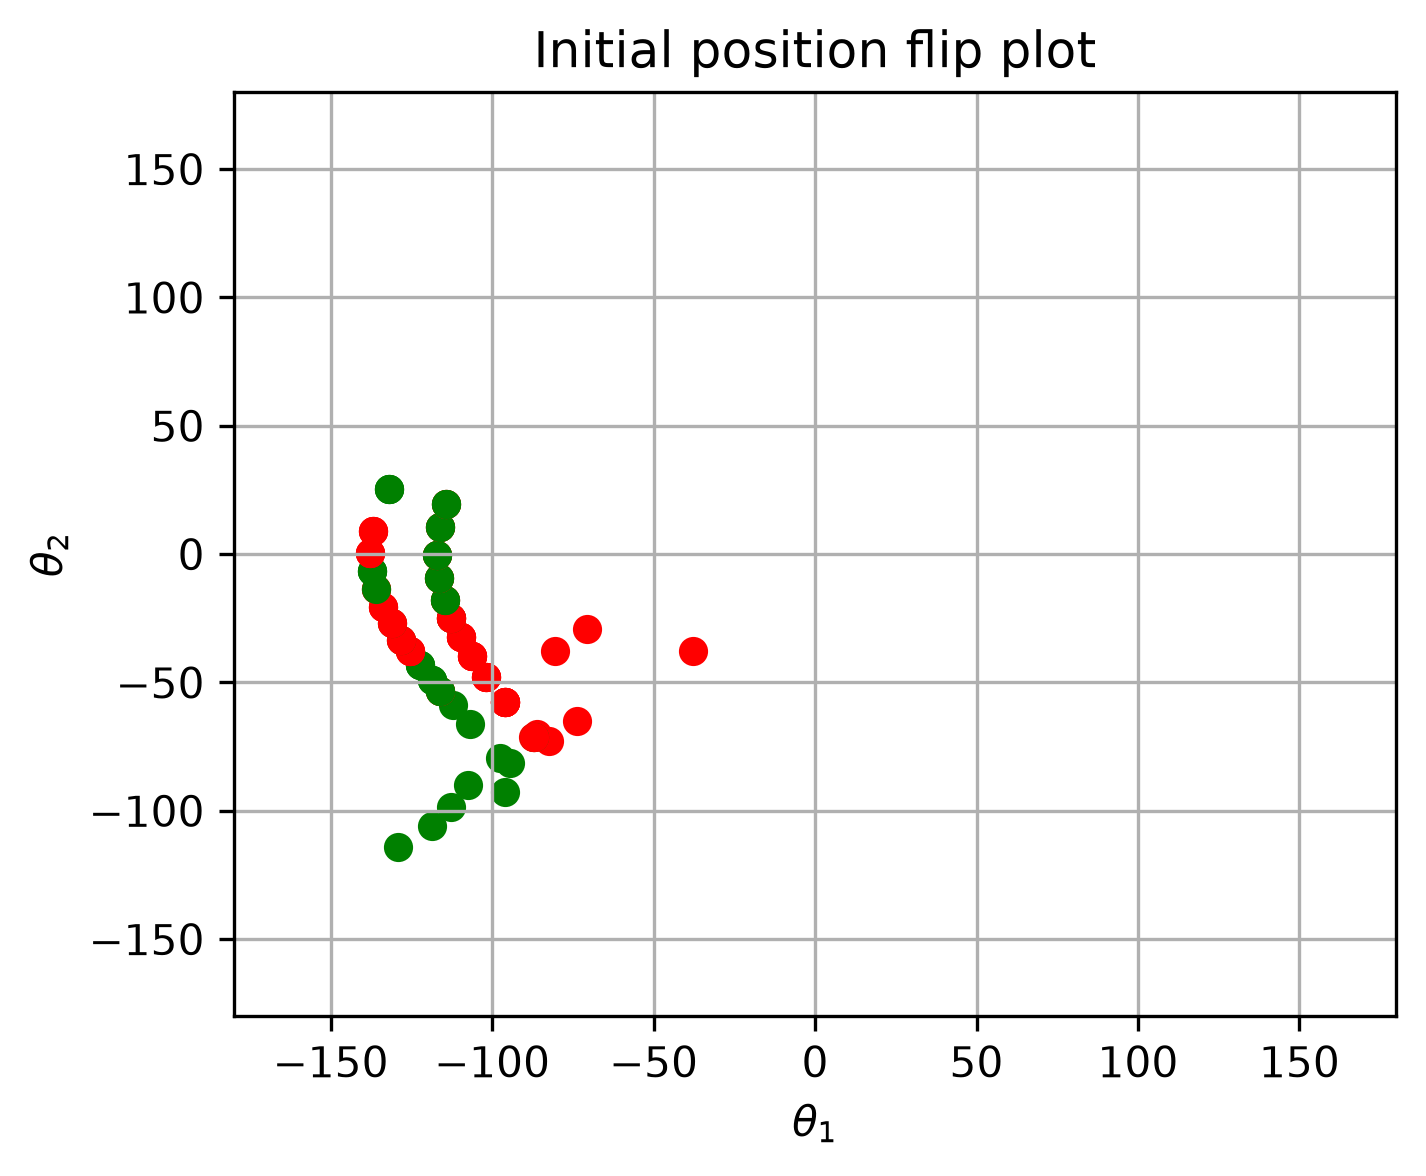

In [ ]:

fig, ax = plt.subplots(figsize=(5, 4), dpi=300)
for i,_ in enumerate(X):
    if flip[i] == 0:
        color = "red"
    else:
        color = "green"
    ax.scatter(theta_1[i] , theta_2[i], color=color)

# critical-energy contour on a grid (degrees for the axes, radians for the energy)
th1_grid, th2_grid = np.meshgrid(np.linspace(-180, 180, 600), np.linspace(-180, 180, 600))
V_grid = pot_energy(np.deg2rad(th1_grid), np.deg2rad(th2_grid))

ax.contour(th1_grid, th2_grid, V_grid, levels=[V_crit], colors="black", linewidths=1.2)
# optional: lightly shade the region where flipping is energetically possible
ax.contourf(th1_grid, th2_grid, V_grid, levels=[V_crit, V_grid.max()], colors="gray", alpha=0.15)
ax.plot([], [], color="black", label=r"$V = V_\mathrm{crit}$")  # legend handle
ax.legend(loc="upper right", fontsize=7)


ax.set_xlabel(r"$\theta_1$")
ax.set_ylabel(r"$\theta_2$")
ax.set_title("Initial position flip plot")
ax.set_xlim(-180,180)
ax.set_ylim(-180,180)
ax.grid()
#plt.legend()
#plt.tight_layout()
#save_dir.mkdir(exist_ok=True)
#fig.savefig(save_dir / f"{res['group']}_{res['name']}.pdf")
#plt.close(fig)
plt.show()